In [1]:
import pandas as pd

In [2]:
import numpy as np

In [52]:
from sklearn.metrics import mutual_info_score

In [53]:
from sklearn.model_selection import train_test_split

### Reading data

The basic file with dataset is in folder ECCOMERCE

In [3]:
data0 = pd.read_csv('ECOMMERCE/ecommerce_customer_churn_dataset.csv')

# Inspecting data

In [4]:
data0.head() #first 5 rows

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4


In [5]:
data0.shape

(50000, 25)

The set has 
- 25 columns - categories
- 50k inputs enumerated from 0 to 49999

EXPLANATION NR 1
- loc method refers to labels, so $.loc[2]$  refers not to second row but row labeled with 2 (pandas allows to very wide range of indexing not only nuemrical and ordered)
- iloc method refers to ordered positon - so we for example can use $.iloc[-1]$ since -1 in python refers to counting from the end, but $.loc[-1]$ will not work in basic indexing since no row has  -1 labelling (unless we set such indexing that -1 occurs as a label !)

In [6]:
data0.loc[49999]

Age                                 56.0
Gender                              Male
Country                               UK
City                               Leeds
Membership_Years                     2.2
Login_Frequency                      2.0
Session_Duration_Avg                18.2
Pages_Per_Session                    NaN
Cart_Abandonment_Rate               46.0
Wishlist_Items                       0.0
Total_Purchases                      9.0
Average_Order_Value               132.67
Days_Since_Last_Purchase            37.0
Discount_Usage_Rate                  2.9
Returns_Rate                         3.5
Email_Open_Rate                      0.0
Customer_Service_Calls               7.0
Product_Reviews_Written              0.0
Social_Media_Engagement_Score        0.0
Mobile_App_Usage                     4.2
Payment_Method_Diversity             1.0
Lifetime_Value                   1072.61
Credit_Balance                     612.0
Churned                                0
Signup_Quarter  

In [8]:
data0.iloc[-1] #Here data0.loc[-1] will not work !

Age                                 56.0
Gender                              Male
Country                               UK
City                               Leeds
Membership_Years                     2.2
Login_Frequency                      2.0
Session_Duration_Avg                18.2
Pages_Per_Session                    NaN
Cart_Abandonment_Rate               46.0
Wishlist_Items                       0.0
Total_Purchases                      9.0
Average_Order_Value               132.67
Days_Since_Last_Purchase            37.0
Discount_Usage_Rate                  2.9
Returns_Rate                         3.5
Email_Open_Rate                      0.0
Customer_Service_Calls               7.0
Product_Reviews_Written              0.0
Social_Media_Engagement_Score        0.0
Mobile_App_Usage                     4.2
Payment_Method_Diversity             1.0
Lifetime_Value                   1072.61
Credit_Balance                     612.0
Churned                                0
Signup_Quarter  

One can note already that they are missing values !

In [6]:
COLUMNS = list(data0.columns)
COLUMNS

['Age',
 'Gender',
 'Country',
 'City',
 'Membership_Years',
 'Login_Frequency',
 'Session_Duration_Avg',
 'Pages_Per_Session',
 'Cart_Abandonment_Rate',
 'Wishlist_Items',
 'Total_Purchases',
 'Average_Order_Value',
 'Days_Since_Last_Purchase',
 'Discount_Usage_Rate',
 'Returns_Rate',
 'Email_Open_Rate',
 'Customer_Service_Calls',
 'Product_Reviews_Written',
 'Social_Media_Engagement_Score',
 'Mobile_App_Usage',
 'Payment_Method_Diversity',
 'Lifetime_Value',
 'Credit_Balance',
 'Churned',
 'Signup_Quarter']

There is 25 columns
- the target is 'Churned'
- 24 columns: 0:22 AND 24 are FEATURES of the model

Target column is not the last column - let's change it

In [10]:
COLUMNS[23], COLUMNS[24] = COLUMNS[24], COLUMNS[23] # in one line
data0 = data0[COLUMNS]

In [11]:
data0.columns #checking

Index(['Age', 'Gender', 'Country', 'City', 'Membership_Years',
       'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session',
       'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance',
       'Signup_Quarter', 'Churned'],
      dtype='str')

Extracting feature columns for future reference

In [12]:
FEATURES = COLUMNS[:24]

### Dealing with categories

Checking dtypes in dataset

In [13]:
data0.dtypes

Age                              float64
Gender                               str
Country                              str
City                                 str
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Signup_Quarter                       str
Churned         

The target has data type int64 and is categorical type taking binary values only - the problem before machine learning is classification problem

Dividing features into numerical and categorical:
Not all not-str dtypes are numerical (continous):
- Payment Method Diversity is categorical feature (like number of seats/doors in a car)

In [14]:
data0['Payment_Method_Diversity'].unique()

array([ 1.,  3., nan,  4.,  2.,  5.])

In [15]:
data0['Payment_Method_Diversity'] = data0['Payment_Method_Diversity'].astype('str')

In [16]:
data0.select_dtypes(include = 'str').head()

,Gender,Country,City,Payment_Method_Diversity,Signup_Quarter
0,Male,France,Marseille,1.0,Q1
1,Male,UK,Manchester,3.0,Q4
2,Female,Canada,Vancouver,NaN,Q4
3,Female,USA,New York,3.0,Q1
4,Male,India,Delhi,4.0,Q4


In [17]:
data0.select_dtypes(exclude = 'str').dtypes

Age                              float64
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
dtype: object

In [18]:
data0.select_dtypes(include = 'str').tail()

,Gender,Country,City,Payment_Method_Diversity,Signup_Quarter
49995,Female,USA,Los Angeles,1.0,Q2
49996,Male,USA,Chicago,4.0,Q3
49997,Female,USA,Phoenix,1.0,Q1
49998,Female,USA,Chicago,3.0,Q2
49999,Male,UK,Leeds,1.0,Q3


Defining the columns with sepcific datatype:

In [20]:
NUM_FEATURES = list(data0.iloc[:,:24].select_dtypes(exclude = 'str').dtypes.index)
CAT_FEATURES = list(data0.iloc[:,:24].select_dtypes(include = 'str').dtypes.index)

For aesthetic reasons, the the order of the columns will be changed to num + cat

In [21]:
FEATURES = NUM_FEATURES + CAT_FEATURES
COLUMNS = FEATURES + ['Churned']

In [22]:
data0 = data0[COLUMNS]

In [23]:
data0.columns # well done

Index(['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg',
       'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items',
       'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Lifetime_Value',
       'Credit_Balance', 'Gender', 'Country', 'City',
       'Payment_Method_Diversity', 'Signup_Quarter', 'Churned'],
      dtype='str')

Now first colums represtnt nuemrical values (continous) and last 5, except target, are categorical

### Inspecting missing values

In [22]:
data0[NUM_FEATURES].isna().sum()

Age                              2495
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Lifetime_Value                      0
Credit_Balance                   5500
dtype: int64

In [39]:
data0[CAT_FEATURES].isna().sum()

Gender                         0
Country                        0
City                           0
Payment_Method_Diversity    2500
Signup_Quarter                 0
dtype: int64

The data has a missing values, the possibilities to deal with it:
- omitting columns with missing values 
- omitting rows with missing values
- set some values in place of Nan
1. First option will work only if there is a lot of missing values in a columns or feature is not such important
2. Second can be used when can allow ourselves to lost some data
3. Possible option are using 0 (conservative choice), mean, median. In the case of str mean,median has no sense, 0 neither. Median can be subsituted by mode - most frequent value. If it comes about numerical features median and mean can achieve similar results, but it depends on the statistical distributions.
******************************************
Median/Mode is a safe choice and it will be used further

We can get many basic information abour data with follwing command:

In [24]:
data0[NUM_FEATURES].describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,46500.000000,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,50000.000000,44500.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,41.997485,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,1440.626292,1966.233258
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,21.373642,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,907.249443,1225.072166
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,0.240000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,25.300000,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,789.817500,1049.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,40.200000,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,1243.415000,1896.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,57.000000,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,1874.000000,2791.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,116.640000,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,8987.240000,7197.000000


Note that aggregation methods omit na-values by deafault
Some feature has smaller count than 50k - na-valueas were excluded

In [34]:
data0[CAT_FEATURES].describe()

,Gender,Country,City,Payment_Method_Diversity,Signup_Quarter
count,50000,50000,50000,47500,50000
unique,3,8,40,5,4
top,Female,USA,Houston,2.0,Q3
freq,25116,17384,3549,16699,12558


The medians are taken for nuemrical values and mode (the most frequent values) are taken dor categorical features:

In [25]:
NUM_MEDIANS = data0[NUM_FEATURES].median()
CAT_MODE = data0[CAT_FEATURES].mode().iloc[0] # mode alone return DataFrame, .iloc[0] changes it to Series!!!

In [26]:
NUM_MEDIANS

Age                                38.000
Membership_Years                    2.500
Login_Frequency                    11.000
Session_Duration_Avg               26.800
Pages_Per_Session                   8.400
Cart_Abandonment_Rate              58.100
Wishlist_Items                      4.000
Total_Purchases                    12.000
Average_Order_Value               112.970
Days_Since_Last_Purchase           21.000
Discount_Usage_Rate                40.200
Returns_Rate                        5.400
Email_Open_Rate                    19.700
Customer_Service_Calls              5.000
Product_Reviews_Written             2.000
Social_Media_Engagement_Score      27.600
Mobile_App_Usage                   18.600
Lifetime_Value                   1243.415
Credit_Balance                   1896.000
dtype: float64

In [27]:
CAT_MODE

Gender                       Female
Country                         USA
City                        Houston
Payment_Method_Diversity        2.0
Signup_Quarter                   Q3
Name: 0, dtype: str

# Replacing Missing Values 

### Checking correation coefficients

We can use method dataframe.corr() to calculate matrix coeffcient

In version after 2.0.0 the 'numeric_only' param is set to be False - with non-numerical columns it will return error

Correlation with target column:

In [28]:
CorrM0 = data0.corr(method = 'pearson', numeric_only = True)
CorrM0.loc['Churned',:].sort_values()

Pages_Per_Session               -0.231799
Session_Duration_Avg            -0.228010
Mobile_App_Usage                -0.222876
Email_Open_Rate                 -0.222213
Login_Frequency                 -0.204379
Wishlist_Items                  -0.197708
Social_Media_Engagement_Score   -0.191792
Product_Reviews_Written         -0.181225
Total_Purchases                 -0.160029
Credit_Balance                  -0.156921
Age                             -0.102849
Discount_Usage_Rate             -0.077121
Lifetime_Value                  -0.010684
Membership_Years                -0.000623
Average_Order_Value              0.042288
Returns_Rate                     0.054189
Days_Since_Last_Purchase         0.153360
Cart_Abandonment_Rate            0.277963
Customer_Service_Calls           0.291103
Churned                          1.000000
Name: Churned, dtype: float64

Generally correlations are not so high, 
- best coorelated variables: Customer Service Calls, Cart Abandonment Rate, Pares Per Session (negative correlation also are important)
- It comes out hat Membership Years has the worst correlation 

For categorical variables we can use mutual information score:

In [54]:
for x in ['Gender', 'City', 'Country', 'Signup_Quarter']:
    a = mutual_info_score(data0[x],data0['Churned'])
    print(x)
    print('Mutual_info_score: ', a)

Gender
Mutual_info_score:  2.924768098717251e-05
City
Mutual_info_score:  0.00042454975872763603
Country
Mutual_info_score:  9.493423286578706e-05
Signup_Quarter
Mutual_info_score:  9.142998809053005e-05


It looks that are quiet irrelevant, we can later compeare it with feature importance taken from  trees (Payment_Method_Diversity is ignored since contains NaN - what returns error)

Let's check shift of correlation coeff with filled nan values:

In [32]:
data0[NUM_FEATURES].fillna(value = NUM_MEDIANS, inplace = False).corrwith(data0.loc[:,'Churned']).sort_values()

Pages_Per_Session               -0.224708
Session_Duration_Avg            -0.219512
Email_Open_Rate                 -0.216233
Mobile_App_Usage                -0.211376
Login_Frequency                 -0.204379
Wishlist_Items                  -0.189569
Social_Media_Engagement_Score   -0.179829
Product_Reviews_Written         -0.174459
Total_Purchases                 -0.160029
Credit_Balance                  -0.147990
Age                             -0.100511
Discount_Usage_Rate             -0.074152
Lifetime_Value                  -0.010684
Membership_Years                -0.000623
Average_Order_Value              0.042288
Returns_Rate                     0.051122
Days_Since_Last_Purchase         0.148015
Cart_Abandonment_Rate            0.277963
Customer_Service_Calls           0.290384
dtype: float64

In [33]:
data0[NUM_FEATURES].fillna(value = 0, inplace = False).corrwith(data0.loc[:,'Churned']).sort_values()

Email_Open_Rate                 -0.223034
Session_Duration_Avg            -0.221985
Login_Frequency                 -0.204379
Pages_Per_Session               -0.193009
Wishlist_Items                  -0.177308
Mobile_App_Usage                -0.176641
Product_Reviews_Written         -0.168212
Social_Media_Engagement_Score   -0.163932
Total_Purchases                 -0.160029
Credit_Balance                  -0.132607
Age                             -0.071164
Discount_Usage_Rate             -0.058823
Lifetime_Value                  -0.010684
Membership_Years                -0.000623
Average_Order_Value              0.042288
Returns_Rate                     0.046995
Days_Since_Last_Purchase         0.143585
Cart_Abandonment_Rate            0.277963
Customer_Service_Calls           0.287303
dtype: float64

Generally it doesn't have significant impact - comparing with na-not-containing records. Also the results with filling zeros and medians are not divergent. The fillin with zeros has greater impact on negative correlation than postive corerlation coeffs. 

### Inspecting descrieb output above one can note that that some people has age 200y:

In [34]:
data0.loc[data0['Age']  > 100, ['Age','Churned']] # it's strage, people's lifespan is shorter

,Age,Churned
6715,150.0,0
8809,200.0,0
12960,150.0,0
16924,150.0,0
17932,150.0,0
18348,200.0,0
22233,200.0,0
23572,200.0,0
24876,200.0,0
34447,200.0,0


In [35]:
data0.loc[data0['Age']  > 100, ['Age','Churned']].corr()

,Age,Churned
Age,1.000000,-0.050252
Churned,-0.050252,1.000000


In [36]:
data0.loc[data0['Age'] < 100, 'Age'].median()

np.float64(37.0)

In [37]:
NUM_MEDIANS['Age'] # it's small change because 

np.float64(38.0)

In [38]:
data0['Age'].mode()

0    18.0
Name: Age, dtype: float64

Such records with age >100 is a few, hwoever we can get rid of them:

Try to replace it with median:

In [39]:
# the median counting from records exluding outliers are more reliable for me:
med = data0.loc[data0['Age'] < 100, 'Age'].median()

prototype = data0['Age'].replace(to_replace=[150,200], value = med)

pd.DataFrame(prototype.fillna(prototype.median())).corrwith(data0.Churned)

Age   -0.102308
dtype: float64

It does not have so much impact at least on coorelation

## Filling

We now define final data for spliting which will be used to tarin datasets

In [42]:
data = data0

Substituting age columns with new column without age above 100 

In [43]:
data.Age = prototype

In [44]:
data.loc[data['Age']> 100, 'Age'] #checking

Series([], Name: Age, dtype: float64)

DEfining medians for filling NaN's

In [45]:
MEDIANS = data[NUM_FEATURES].median()
data[NUM_FEATURES] = data[NUM_FEATURES].fillna(value = MEDIANS)

In [46]:
data[NUM_FEATURES].isna().sum().values #checking

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

Now Categorical Features:

In [48]:
data[CAT_FEATURES] = data[CAT_FEATURES].fillna(CAT_MODE)

In [49]:
data[CAT_FEATURES].isna().sum().values #checking

array([0, 0, 0, 0, 0])

GG!!

# Spitting

We gonna use a skl.preprocessing

In [55]:
data_train_full, data_test = train_test_split(data,test_size= 0.15, random_state=42)
data_train, data_val = train_test_split(data_train_full,test_size= 0.15, random_state=42)

REMARK - it's worth to check that our sampes covers all categories:
- We will gona use OHE and if in some sample some categort will be missing then we get diffrent number of 'dummy columns' what could be problematic when we would like to test our prediction (since size of matrices can be diffrent)
******************************************
Here all samples cover all uniqe categories 

In [57]:
data[CAT_FEATURES].nunique()

Gender                       3
Country                      8
City                        40
Payment_Method_Diversity     5
Signup_Quarter               4
dtype: int64

In [58]:
data_train[CAT_FEATURES].nunique()

Gender                       3
Country                      8
City                        40
Payment_Method_Diversity     5
Signup_Quarter               4
dtype: int64

In [59]:
data_test[CAT_FEATURES].nunique()

Gender                       3
Country                      8
City                        40
Payment_Method_Diversity     5
Signup_Quarter               4
dtype: int64

In [60]:
data_val[CAT_FEATURES].nunique()

Gender                       3
Country                      8
City                        40
Payment_Method_Diversity     5
Signup_Quarter               4
dtype: int64

# Savings

Before saving let's reset index:

In [61]:
data_test = data_test.reset_index(drop = True)
data_val = data_val.reset_index(drop = True)
data_train = data_train.reset_index(drop = True)

In [64]:
data_val.head() #quick check --> ok

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Gender,Country,City,Payment_Method_Diversity,Signup_Quarter,Churned
0,18.0,1.9,13.0,34.3,9.0,64.8,4.0,13.0,171.68,21.0,...,33.5,26.5,1958.07,2217.0,Male,UK,Glasgow,1.0,Q2,1
1,30.0,2.5,4.0,22.3,8.4,56.0,4.0,10.4,135.55,54.0,...,27.6,4.6,1260.49,1927.0,Female,USA,New York,2.0,Q4,0
2,38.0,1.6,5.0,17.2,6.3,74.3,4.0,6.0,125.10,18.0,...,14.2,13.2,629.95,1139.0,Male,Canada,Vancouver,1.0,Q1,1
3,31.0,5.6,11.0,37.9,10.5,50.2,8.0,16.0,109.60,33.0,...,31.8,18.6,1841.11,1904.0,Female,UK,London,2.0,Q1,0
4,24.0,2.4,12.0,42.9,10.1,49.5,8.0,16.9,115.24,13.0,...,21.3,33.2,1208.08,396.0,Male,Japan,Tokyo,1.0,Q4,0


In [65]:
data_test.to_json('ECOMMERCE/test_data.json')
data_train.to_json('ECOMMERCE/train_data.json')
data_val.to_json('ECOMMERCE/val_data.json')

One can generally use another format - especially .csv  would be ligther - here files are saved in json format for a sport

# Visualization

In [36]:
import seaborn as sea

<Axes: ylabel='Count'>

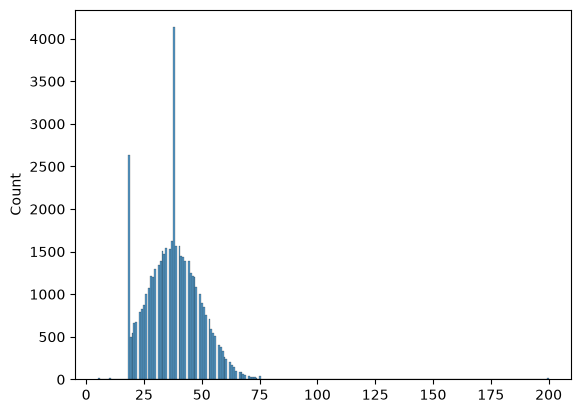

In [42]:
sea.histplot(data = data0['Age'].values)

In [44]:
data0.loc[ data0['Age'] >100 ,"Age"]

6715     150.0
8809     200.0
12960    150.0
16924    150.0
17932    150.0
18348    200.0
22233    200.0
23572    200.0
24876    200.0
34447    200.0
35800    150.0
38932    200.0
39434    150.0
40068    200.0
40909    200.0
42707    150.0
45628    150.0
46351    150.0
47696    200.0
49331    200.0
Name: Age, dtype: float64

In [46]:
data0['Age'].nunique()

62

<Axes: xlabel='Login_Frequency', ylabel='Count'>

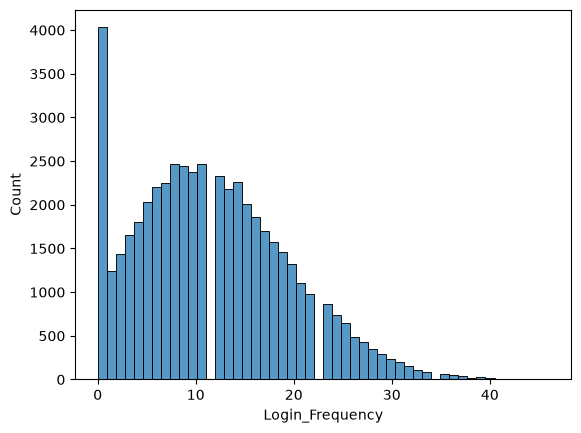

In [48]:
sea.histplot(data = data0['Login_Frequency'], bins = 50)

<Axes: xlabel='Membership_Years', ylabel='Count'>

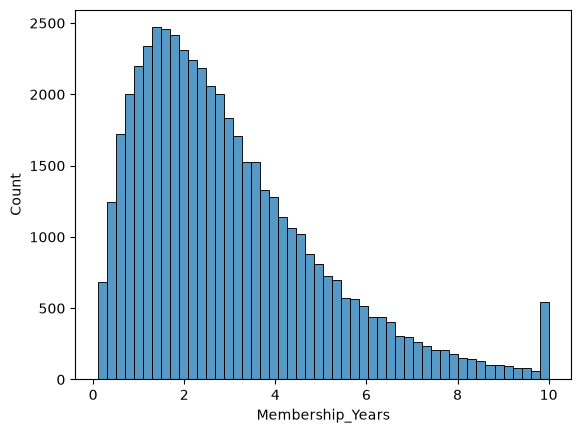

In [49]:
sea.histplot(data = data0['Membership_Years'], bins = 50)

<Axes: xlabel='Session_Duration_Avg', ylabel='Count'>

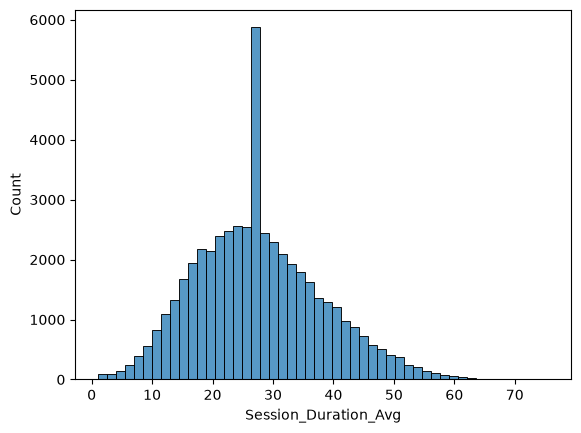

In [50]:
sea.histplot(data = data0['Session_Duration_Avg'], bins = 50)

<Axes: xlabel='Pages_Per_Session', ylabel='Count'>

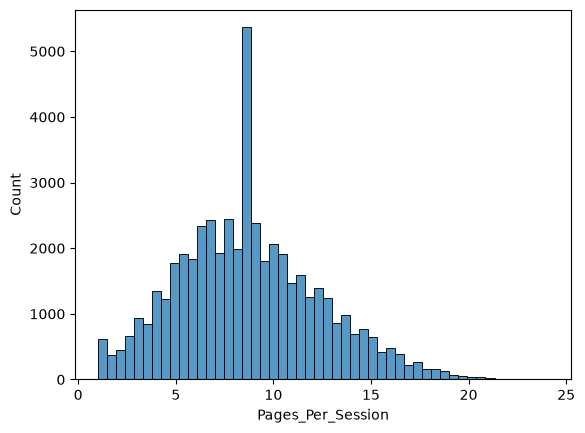

In [52]:
sea.histplot(data = data0['Pages_Per_Session'], bins = 50)

<Axes: xlabel='Wishlist_Items', ylabel='Count'>

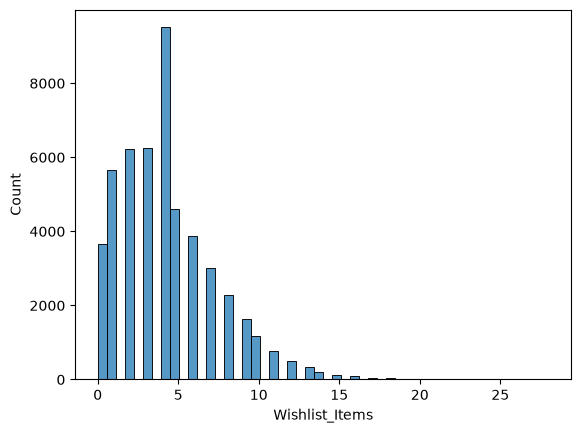

In [56]:
sea.histplot(data = data0['Wishlist_Items'], bins = 50, log_scale = False)

Most of above columns has non-symmetric distribution with one or two "outliers'. Generally one can expect the non-lieanr compex realtion between the diffrent markers of customer's bevavior and churning variable. Also the quiete small correlation coeffs means that there is no one and generall marker of churning. There is rather many small impacts from diffrent features